## Rama B — Capítulo 3

Este cuaderno genera las Figuras 3.1–3.3 del Capítulo 3 (propagación en la celda) para la Rama B (semilla a 852 nm, señal a 794 nm). Cada figura es la evaluación directa de una expresión cerrada del PDF, sin integración numérica.

| Figura | Cantidad | Ecuaciones | Archivo |
|---|---|---|---|
| 3.1 | Transmisión de la semilla, $T_3=e^{-2\kappa_3L}$, frente a $\Delta_3$ para varias densidades $N$ | (3.26)–(3.27) | `figuras/F3-1_transmision_semilla.pdf` |
| 3.2 | $\lvert\chi^{(3)}_{P,B}\rvert^2$ normalizada en el plano $(\Delta_2,\Delta_3)$ | (2.84) | `figuras/F3-2_mapa_celda_delgada.pdf` |
| 3.3 | (a) $\lvert L_{\text{ef}}\rvert^2/L^2$ con $\Delta k=0$; (b) intensidad de la señal con $\Delta_2=0$ | (3.53) y (3.56) | `figuras/F3-3_longitud_efectiva.pdf` |

**Convenciones**

- Las tasas y desintonías van **divididas por $2\pi$, en MHz**, como en el Capítulo 2.
- $\kappa_3$ se calcula **en SI** (m⁻¹), porque el exponente de $T_3$ es un número absoluto.
- Todas las constantes físicas se importan de `constants.py` (raíz del repositorio).
- Las figuras se guardan en `figuras/` en PDF; los mapas se rasterizan.

In [2]:
import os
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from constants import (c, hbar, eps0, g_ba, g_ca, g_cb, G_ab, w_ba, w_ca, w_cb,
                       mu_ba, mu_cb, L_celda, n_Cs)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

os.makedirs("figuras", exist_ok=True)

def guardar(fig, nombre):
    # Guarda la figura en figuras/<nombre>.pdf; dpi fija la resolución de los mapas rasterizados
    ruta = os.path.join("figuras", f"{nombre}.pdf")
    fig.savefig(ruta, bbox_inches="tight", dpi=300)
    print(f"Guardada: {ruta}")

## 1. Parámetros del modelo

La transmisión de la semilla, (3.26)–(3.27), depende de:

| Símbolo | Significado | De dónde sale |
|---|---|---|
| $\gamma_{ba}$ | decaimiento de la coherencia $\rho_{ba}$, ancho de la línea D2 | `g_ba` de `constants.py` |
| $\lvert\mu_{ba}\rvert$ | momento dipolar de $\lvert a\rangle\leftrightarrow\lvert b\rangle$ | `mu_ba` de `constants.py` |
| $N$ | densidad de átomos de Cs | `n_Cs(T)` de `constants.py`: presión de vapor (4.2) y gas ideal (4.3), a la temperatura de la celda |
| $L$ | longitud de la celda | `L_celda` de `constants.py` (valor del PDF, por confirmar con el laboratorio) |
| $k_3$ | número de onda de vacío de la semilla, $\omega_3/c$ | frecuencia del láser de 852 nm (sección 2) |

**Momento dipolar.** `constants.py` define el dipolo efectivo de dos niveles, $\lvert\mu_{ba}\rvert^2 = \lvert\langle 6S_{1/2}\Vert e\mathbf r\Vert 6P_{3/2}\rangle\rvert^2/(2J_b+1)$, con el que la tasa de emisión espontánea de dos niveles, $\omega_{ba}^3\lvert\mu_{ba}\rvert^2/(3\pi\varepsilon_0\hbar c^3)$, reproduce $\Gamma_{D2}=2\gamma_{ba}$; la celda de abajo imprime la comparación. En ese sentido el modelo es coherente: el mismo dipolo fija el ancho de la línea y la intensidad de la absorción. Los momentos dipolares efectivos corresponden a un átomo de dos niveles sin degeneración, de modo que las formas de las resonancias son correctas pero las magnitudes absolutas llevan un factor de orden 1 por la polarización.

Las opciones de graficación (temperaturas de la celda, número de puntos, rangos de los ejes) no son constantes físicas y pueden ajustarse.

In [3]:
# --- Constantes físicas, desde constants.py ---------------------------------
# constants.py está en SI y rad/s; las desintonías van divididas por 2π, en MHz.
MHz = 2 * np.pi * 1e6   # rad/s que corresponden a 1 MHz de ω/2π

gamma_ba = g_ba / MHz             # γ_ba/2π : decaimiento de la coherencia ρ_ba (Γ_D2/2)
gamma_ca = g_ca / MHz             # γ_ca/2π : decaimiento de la coherencia de dos fotones ρ_ca
gamma_cb = g_cb / MHz             # γ_cb/2π : decaimiento de la coherencia ρ_cb
Gamma_ab = G_ab / MHz             # Γ_ab/2π : decaimiento de población |b> -> |a>

# Frecuencias de transición /2π, en MHz (las usa `frecuencias_laser`)
nu_ba, nu_ca, nu_cb = w_ba / MHz, w_ca / MHz, w_cb / MHz

# --- Opciones de graficación -----------------------------------------------
N_PUNTOS   = 4001               # resolución de las curvas
RANGO_T12  = 2.5                # semiancho del eje, en múltiplos del mayor semiancho a T3 = 1/2
D2_FIJA    = 0.0                # desintonía de dos fotones del bombeo (MHz); T3 no depende de ella

# --- Comprobación del momento dipolar ---------------------------------------
Gamma_mu = w_ba**3 * mu_ba**2 / (3 * np.pi * eps0 * hbar * c**3) / MHz
print(f"|mu_ba| = {mu_ba:.4e} C m      L = {L_celda * 100:.2f} cm")
print(f"Gamma(mu_ba)/2pi = {Gamma_mu:.4f} MHz   2 gamma_ba/2pi = {2 * gamma_ba:.4f} MHz   "
      f"(diferencia relativa {abs(Gamma_mu / (2 * gamma_ba) - 1):.1e})")

|mu_ba| = 2.6809e-29 C m      L = 7.18 cm
Gamma(mu_ba)/2pi = 5.2067 MHz   2 gamma_ba/2pi = 5.2227 MHz   (diferencia relativa 3.1e-03)


## 2. Desintonías que se controlan en la Rama B

Las dos perillas son la desintonía de dos fotones del bombeo, $\Delta_2 = \omega_{ca} - 2\omega_1$, y la de la semilla, $\Delta_3 = \omega_{ba} - \omega_3$, (2.6). De ellas salen las frecuencias de los láseres, y la conservación de la energía (2.5) fija la de la señal:

$$
\omega_1 = \frac{\omega_{ca}-\Delta_2}{2}, \qquad
\omega_3 = \omega_{ba}-\Delta_3, \qquad
\omega_2 = 2\omega_1-\omega_3 .
$$

Las desintonías restantes son, por (2.6) y (2.8),

$$
\Delta_1 = \omega_{ba}-\omega_1, \qquad \delta_2 = \omega_{cb}-\omega_2 = \Delta_2-\Delta_3 .
$$

`frecuencias_laser` y `desintonias` son las mismas del cuaderno del Capítulo 2. `numero_de_onda` da el número de onda de vacío de cada campo, $k_j=\omega_j/c$, como en (3.17) y (3.19), a partir de la frecuencia del láser.

In [4]:
def frecuencias_laser(D2, D3):
    # Frecuencias /2π (MHz) de los tres campos a partir de las dos perillas (Δ2, Δ3)
    nu1 = (nu_ca - D2) / 2    # bombeo, 822 nm
    nu3 = nu_ba - D3          # semilla, 852 nm
    nu2 = 2 * nu1 - nu3       # señal, 794 nm: conservación de la energía (2.5)
    return nu1, nu2, nu3

def desintonias(D2, D3):
    # Devuelve (Δ1, δ2) según (2.6) y (2.8)
    nu1, nu2, nu3 = frecuencias_laser(D2, D3)
    D1 = nu_ba - nu1
    d2 = D2 - D3              # = nu_cb - nu2, sin el redondeo de restar números ~1e8 MHz
    return D1, d2

def numero_de_onda(nu):
    # Número de onda de vacío k = ω/c [rad/m], con nu = ω/2π en MHz
    return 2 * np.pi * nu * 1e6 / c

def lorentziana(x, gamma):
    # Perfil lorentziano normalizado a 1 en x = 0.
    return gamma**2 / (x**2 + gamma**2)

D1_0, _ = desintonias(D2_FIJA, 0.0)
k3_res = numero_de_onda(frecuencias_laser(D2_FIJA, 0.0)[2])
print(f"Delta1/2pi (Delta2 = {D2_FIJA:g}) = {D1_0 / 1e6:.4f} THz")
print(f"k3 (Delta3 = 0) = {k3_res:.6e} rad/m   ->   lambda3 = {2 * np.pi / k3_res * 1e9:.3f} nm")

Delta1/2pi (Delta2 = 0) = -12.7792 THz
k3 (Delta3 = 0) = 7.371626e+06 rad/m   ->   lambda3 = 852.347 nm


## 3. Propagación de la semilla (Sección 3.4.1)

$$
\tilde E_3(z) = \tilde E_3(0)\exp\!\Big(\frac{ik_3}{2}\chi^{(1)}(\omega_3)\,z\Big). \tag{3.23}
$$

Con $\chi^{(1)} = \chi^{(1)\prime}+i\chi^{(1)\prime\prime}$,

$$
\frac{ik_3}{2}\chi^{(1)}(\omega_3) = -\kappa_3+i\beta_3,
\qquad \kappa_3 \equiv \frac{k_3\chi^{(1)\prime\prime}}{2},\quad \beta_3 \equiv \frac{k_3\chi^{(1)\prime}}{2},
\qquad
\tilde E_3(z) = \tilde E_3(0)\,e^{(-\kappa_3+i\beta_3)z}. \tag{3.24–3.25}
$$

Con $\chi^{(1)}(\omega_3)$ de (2.77) y su separación (2.79):

$$
\kappa_3 = \frac{k_3N\lvert\mu_{ba}\rvert^2}{2\varepsilon_0\hbar}\,\frac{\gamma_{ba}}{\Delta_3^2+\gamma_{ba}^2},
\qquad
\beta_3 = \frac{k_3N\lvert\mu_{ba}\rvert^2}{2\varepsilon_0\hbar}\,\frac{\Delta_3}{\Delta_3^2+\gamma_{ba}^2},
\qquad
\beta_3 = \frac{\Delta_3}{\gamma_{ba}}\,\kappa_3. \tag{3.26}
$$

**Unidades.** En (3.26) las desintonías y $\gamma_{ba}$ van en rad/s. Como aquí se usan divididas por $2\pi$ en MHz, el denominador de $\chi^{(1)}$ se multiplica por `MHz` $=2\pi\times10^6$.

`chi1` calcula $\chi^{(1)}(\omega_3)$ en SI (adimensional) y `kappa_beta_3` devuelve $(\kappa_3,\beta_3)$ en m⁻¹ a partir de las perillas.

In [5]:
def chi1(D3, N):
    # χ(1)(ω3) del átomo en reposo, ec. (2.77), en SI. D3 en MHz (/2π), N en m^-3.
    return N * mu_ba**2 / (eps0 * hbar * (D3 - 1j * gamma_ba) * MHz)

def kappa_beta_3(D2, D3, N):
    # (κ3, β3) en m^-1, ecs. (3.24) y (3.26), con k3 = ω3/c de la frecuencia del láser de 852 nm
    k3 = numero_de_onda(frecuencias_laser(D2, D3)[2])
    exponente = 1j * k3 / 2 * chi1(D3, N)       # = -κ3 + iβ3
    return -exponente.real, exponente.imag

## 4. Figura 3.1 — Transmisión de la semilla

**Cantidad.** La transmisión en intensidad de la semilla a través de la celda, (3.27),

$$
T_3 = \frac{\lvert\tilde E_3(L)\rvert^2}{\lvert\tilde E_3(0)\rvert^2} = e^{-2\kappa_3L},
$$

con $\kappa_3$ de (3.26) para el átomo en reposo. $2\kappa_3L$ es la profundidad óptica de la semilla; su dependencia con $\Delta_3$ es la de la parte imaginaria de la Figura 2.5, una lorentziana de ancho $\gamma_{ba}$.

**Normalización.** No hay: $T_3$ es adimensional y el exponente es absoluto, así que hacen falta $N$, $\lvert\mu_{ba}\rvert$ y $L$ en SI.

**Barrido.** Se barre la semilla, $\Delta_3$, para varias temperaturas de la celda (`T_C`); cada una da una densidad $N(T)$. La tabla impresa da, para cada una, $\kappa_3$ y $2\kappa_3L$ en resonancia y la desintonía en que $T_3=1/2$, que fija el rango del eje.

In [6]:
T_C  = np.array([30, 40, 50, 70])   # °C. PENDIENTE: el PDF no fija la lista de temperaturas (o densidades)
N_lista = n_Cs(T_C)

print(f"{'T (°C)':>7s} {'N (cm^-3)':>11s} {'kappa3(0) (1/m)':>16s} {'OD0 = 2 kappa3(0) L':>20s} "
      f"{'Delta3_1/2 /2pi (MHz)':>22s}")
D3_medio = []
for TC, N in zip(T_C, N_lista):
    kap0, _ = kappa_beta_3(D2_FIJA, 0.0, N)
    OD0 = 2 * kap0 * L_celda
    D3_12 = gamma_ba * np.sqrt(OD0 / np.log(2) - 1)
    D3_medio.append(D3_12)
    print(f"{TC:7.0f} {N * 1e-6:11.3e} {kap0:16.4e} {OD0:20.4e} {D3_12:22.1f}")

# Factores entre la temperatura más baja y la más alta de T_C
f_N, f_D = N_lista[-1] / N_lista[0], D3_medio[-1] / D3_medio[0]
print(f"De {T_C[0]:.0f} a {T_C[-1]:.0f} °C: N crece x{f_N:.3g}; Delta3_1/2 crece x{f_D:.3g} "
      f"(sqrt del factor de N = {np.sqrt(f_N):.3g})")

 T (°C)   N (cm^-3)  kappa3(0) (1/m)  OD0 = 2 kappa3(0) L  Delta3_1/2 /2pi (MHz)
     30   6.922e+10       1.1969e+04           1.7187e+03                  130.0
     40   1.735e+11       3.0003e+04           4.3084e+03                  205.9
     50   4.101e+11       7.0907e+04           1.0182e+04                  316.5
     70   1.960e+12       3.3883e+05           4.8657e+04                  691.9
De 30 a 70 °C: N crece x28.3; Delta3_1/2 crece x5.32 (sqrt del factor de N = 5.32)


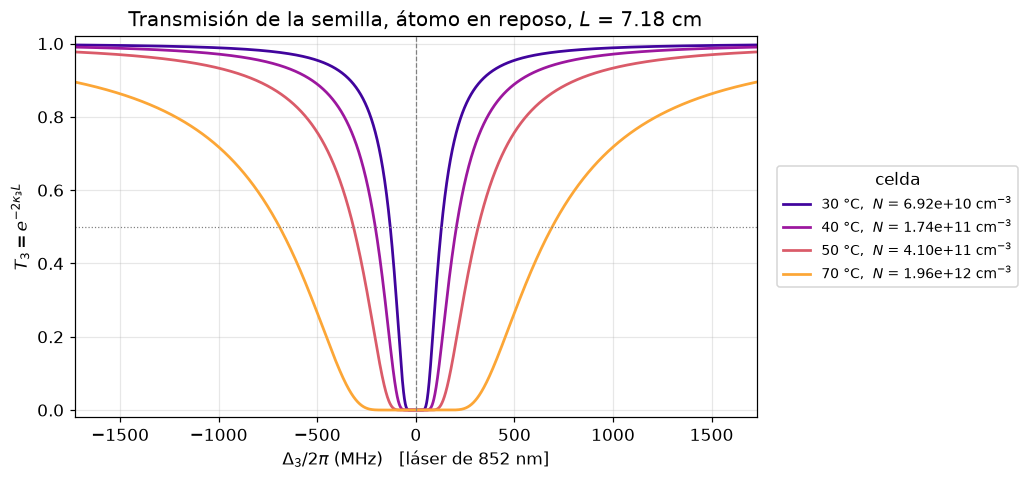

Guardada: figuras\F3-1_transmision_semilla.pdf


In [7]:
lim = RANGO_T12 * max(D3_medio)
D3 = np.linspace(-lim, lim, N_PUNTOS)

fig, ax = plt.subplots(figsize=(8, 4.5))
colores = plt.cm.plasma(np.linspace(0.1, 0.8, len(T_C)))
for TC, N, color in zip(T_C, N_lista, colores):
    kap, _ = kappa_beta_3(D2_FIJA, D3, N)
    T3 = np.exp(-2 * kap * L_celda)
    ax.plot(D3, T3, color=color, lw=1.8,
            label=rf"{TC:.0f} °C,  $N$ = {N * 1e-6:.2e} cm$^{{-3}}$")
ax.axhline(0.5, color="gray", ls=":", lw=0.8)
ax.axvline(0, color="gray", ls="--", lw=0.8)
ax.set_xlim(-lim, lim)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel(r"$\Delta_3/2\pi$ (MHz)   [láser de 852 nm]")
ax.set_ylabel(r"$T_3 = e^{-2\kappa_3 L}$")
ax.set_title(rf"Transmisión de la semilla, átomo en reposo, $L$ = {L_celda * 100:.2f} cm")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9, title="celda")
plt.show()
guardar(fig, "F3-1_transmision_semilla")

**Qué observar.**

- **La celda es opaca en un intervalo ancho alrededor de la D2.** Lejos de la resonancia, (3.26) da $2\kappa_3L\propto N/\Delta_3^2$, así que el ancho del pozo crece como $\sqrt N$: comparar los dos factores de la última línea impresa.
- **El pozo es simétrico en $\Delta_3$**, porque $T_3$ solo depende de $\kappa_3$. La parte real, $\beta_3$, cambia la fase de la semilla y no su intensidad.
- **Átomo en reposo.** La figura da la escala de la absorción lineal del átomo en reposo, no el pozo que se mide: falta el promedio Doppler (Sección 3.6).

## 5. Validez del modelo perturbativo: $s_3$ y $\rho_{bb}^{(2)}$ de la semilla experimental

**Cantidad.** La población de segundo orden de $\lvert b\rangle$, (2.52)–(2.53),

$$
\rho_{bb}^{(2)} = \frac{2\gamma_{ba}}{\Gamma_{ab}}\,\lvert A_3\rvert^2 = \frac{2\gamma_{ba}}{\Gamma_{ab}}\;s_3\,\frac{\gamma_{ba}^2}{\Delta_3^2+\gamma_{ba}^2},
\qquad s_3 \equiv \frac{\lvert\mu_{ba}\tilde E_3(0)\rvert^2}{(\hbar\gamma_{ba})^2},
$$

para la semilla de la medida de detección, en resonancia y desintonizada (`D3_LEJOS`). $\lvert\tilde E_3(0)\rvert^2$ sale de la potencia y de las cinturas medidas del haz de 852 nm (Tabla 4.1), con la intensidad en el eje $I_0 = 2P/(\pi w_{0,W}\,w_{0,V}) = 2\varepsilon_0c\lvert\tilde E_3(0)\rvert^2$.

$\rho_{bb}^{(2)}\ll1$ es la condición de validez del modelo perturbativo. La celda solo imprime los valores.

In [8]:
P_SEMILLA  = 500e-6               # W, potencia de la semilla en la detección a 794 nm (Rama_B/Deteccion_794).
                                  # PENDIENTE: no está en el PDF ni en constants.py
W0_SEMILLA = (47.1e-6, 57.6e-6)   # m, cinturas medidas del haz de 852 nm, ejes W y V (Tabla 4.1)
D3_LEJOS   = 1000.0               # MHz, semilla desintonizada. PENDIENTE: valor ilustrativo, no está en el PDF

def rho_bb2(s3, D3):
    # ρ_bb^(2), ecs. (2.52)–(2.53): (2γ_ba/Γ_ab) |A3|², con |A3|² = s3 γ_ba²/(Δ3² + γ_ba²)
    return (2 * gamma_ba / Gamma_ab) * s3 * lorentziana(D3, gamma_ba)

I0_exp = 2 * P_SEMILLA / (np.pi * W0_SEMILLA[0] * W0_SEMILLA[1])          # W/m², intensidad en el eje
s3_exp = mu_ba**2 * I0_exp / (2 * eps0 * c) / (hbar * gamma_ba * MHz)**2
print(f"Semilla: P = {P_SEMILLA * 1e6:.0f} µW, w0 = {W0_SEMILLA[0] * 1e6:.1f} µm (W) y {W0_SEMILLA[1] * 1e6:.1f} µm (V)")
print(f"s3 = {s3_exp:.3g}")
for D3, nombre in [(0.0, "semilla en resonancia"), (D3_LEJOS, f"semilla desintonizada {D3_LEJOS:g} MHz")]:
    print(f"rho_bb^(2), {nombre}: {rho_bb2(s3_exp, D3):.3g}")

Semilla: P = 500 µW, w0 = 47.1 µm (W) y 57.6 µm (V)
s3 = 5.31e+03
rho_bb^(2), semilla en resonancia: 5.31e+03
rho_bb^(2), semilla desintonizada 1000 MHz: 0.0362


## 6. Figura 3.2 — $\lvert\chi^{(3)}_{P,B}\rvert^2$ en el plano $(\Delta_2,\Delta_3)$

**Cantidad.** El módulo al cuadrado de la susceptibilidad paramétrica de la Rama B, con $K\equiv N\lvert\mu_{ba}\rvert^2\lvert\mu_{cb}\rvert^2/\varepsilon_0\hbar^3$:

$$
\chi^{(3)}_{P,B} = -\frac{K}{(\Delta_1-i\gamma_{ba})(\Delta_2-i\gamma_{ca})(\delta_2-i\gamma_{cb})} \tag{2.84}
$$

Es la dependencia con las desintonías de la intensidad de la señal en el límite de celda delgada, (3.47).

**Normalización.** Se divide por su máximo, de modo que $K$ se cancela: la figura no depende de $N$, $L$ ni de las intensidades. `T_FIG` solo fija el $N$ con que se evalúa $K$.

**Barrido.** $\Delta_2$ y $\Delta_3$ en $\pm$`RANGO_MAPA`, en escala logarítmica, con las rectas $\Delta_2=0$, $\Delta_3=0$ y $\delta_2=0$.

In [9]:
T_FIG = 60.0            # °C, temperatura de la detección a 794 nm (Rama_B/Deteccion_794); N se cancela al normalizar.
                        # PENDIENTE: no está en el PDF ni en constants.py
N_FIG = n_Cs(T_FIG)

def prefactor_K(N):
    # K = N |mu_ba|^2 |mu_cb|^2/(eps0 hbar^3), dividido por MHz^3 porque las desintonías van en MHz
    return N * mu_ba**2 * mu_cb**2 / (eps0 * hbar**3 * MHz**3)

def chi3_PB(D2, D3, N):
    # Fuente paramétrica, ec. (2.84), en m^2/V^2
    D1, d2 = desintonias(D2, D3)
    return -prefactor_K(N) / ((D1 - 1j * gamma_ba) * (D2 - 1j * gamma_ca) * (d2 - 1j * gamma_cb))

def marcar_rectas(ax, lim, color="k"):
    # Marca Δ2 = 0, Δ3 = 0 y δ2 = 0 sobre un mapa con ejes (Δ2, Δ3)
    ax.axvline(0, color=color, ls="--", lw=1)
    ax.axhline(0, color=color, ls=":", lw=1.2)
    ax.plot([-lim, lim], [-lim, lim], color=color, ls="-.", lw=1)
    ax.text(0.02 * lim, 0.9 * lim, r"$\Delta_2=0$", color=color)
    ax.text(0.6 * lim, -0.1 * lim, r"$\Delta_3=0$", color=color)
    ax.text(0.45 * lim, 0.58 * lim, r"$\delta_2=0$", color=color, rotation=45)

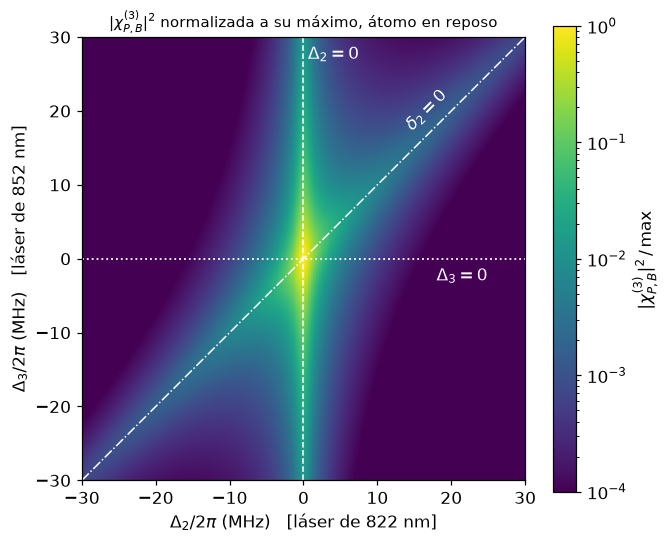

Guardada: figuras\F3-2_mapa_celda_delgada.pdf


In [10]:
RANGO_MAPA = 30.0   # semiancho de los ejes (MHz)
N_MAPA     = 601

eje = np.linspace(-RANGO_MAPA, RANGO_MAPA, N_MAPA)
D2m, D3m = np.meshgrid(eje, eje)
mapa = np.abs(chi3_PB(D2m, D3m, N_FIG))**2
mapa = mapa / mapa.max()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.pcolormesh(eje, eje, mapa, norm=LogNorm(vmin=1e-4, vmax=1), shading="auto", rasterized=True)
marcar_rectas(ax, RANGO_MAPA, color="w")
ax.set_xlim(-RANGO_MAPA, RANGO_MAPA); ax.set_ylim(-RANGO_MAPA, RANGO_MAPA)
ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel(r"$\Delta_2/2\pi$ (MHz)   [láser de 822 nm]")
ax.set_ylabel(r"$\Delta_3/2\pi$ (MHz)   [láser de 852 nm]")
ax.set_title(r"$|\chi^{(3)}_{P,B}|^2$ normalizada a su máximo, átomo en reposo", fontsize=10)
fig.colorbar(im, ax=ax, label=r"$|\chi^{(3)}_{P,B}|^2\,/\,\max$")
plt.show()
guardar(fig, "F3-2_mapa_celda_delgada")

**Qué observar.**

- **Dos crestas**, sobre las rectas $\Delta_2=0$ (resonancia de dos fotones, ancho $\gamma_{ca}$) y $\delta_2=0$ (señal en resonancia, ancho $\gamma_{cb}$); el máximo está en su cruce.
- **No hay cresta sobre $\Delta_3=0$**: $\chi^{(3)}_{P,B}$ no tiene un denominador resonante en $\Delta_3$, y la semilla entra solo a través de $\delta_2=\Delta_2-\Delta_3$.

## 7. Figura 3.3 — Longitud efectiva y espectro de la señal con semilla absorbida

**(a)** La longitud efectiva de generación (3.53), con $\Delta k=0$:

$$
L_{\text{ef}} = \frac{1-e^{-qL}}{q}, \qquad q=\kappa_3+i\beta_3 .
$$

Por (3.26), $\kappa_3L$ es $\tfrac12\,[2\kappa_3(\Delta_3{=}0)L]$ por una lorentziana de ancho $\gamma_{ba}$, y $\beta_3L=(\Delta_3/\gamma_{ba})\,\kappa_3L$. Así, $\lvert L_{\text{ef}}\rvert^2/L^2$ depende solo de $\Delta_3$ y de la profundidad óptica de la semilla en resonancia, $2\kappa_3(\Delta_3{=}0)L$ (`OD0_LISTA`).

**(b)** La intensidad de la señal delgada con semilla absorbida (3.56), con $\Delta_2=0$ y para las mismas profundidades ópticas:

$$
\lvert\tilde E_2(L)\rvert^2 \approx \frac{k_2^2}{4}\bigl\lvert\chi^{(3)}_{P,B}\bigr\rvert^2\lvert\tilde E_1\rvert^4\lvert\tilde E_3(0)\rvert^2\;
\frac{1+e^{-2\kappa_3L}-2e^{-\kappa_3L}\cos\beta_3L}{\kappa_3^2+\beta_3^2} .
$$

**Normalización.** (a) no necesita. (b) se divide por su máximo, de modo que $N$ y las intensidades se cancelan. La línea de trazos es el límite delgado (3.47) con $\Delta_2=0$, una lorentziana de ancho $\gamma_{cb}$.

**Barrido.** Ambas curvas son pares en $\Delta_3$; el eje es logarítmico en $\lvert\Delta_3\rvert$. La celda imprime además la diferencia entre el factor de (3.56) y $\lvert L_{\text{ef}}\rvert^2$ de (3.53), que son la misma cantidad, (3.54)–(3.55).

2 kappa3(0) L de la celda: 30 °C -> 1.72e+03, 40 °C -> 4.31e+03, 50 °C -> 1.02e+04, 70 °C -> 4.87e+04
Factor de (3.56) frente a |L_ef|^2/L^2 de (3.53): diferencia relativa máxima 1.6e-08


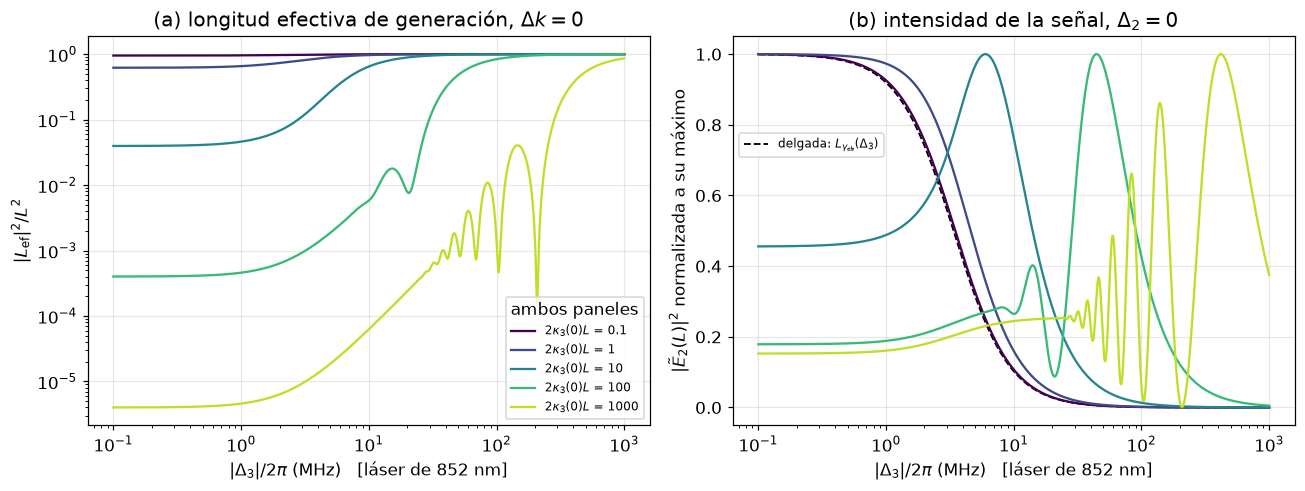

Guardada: figuras\F3-3_longitud_efectiva.pdf


In [11]:
OD0_LISTA = [0.1, 1, 10, 100, 1000]   # 2 κ3(Δ3=0) L. PENDIENTE: el PDF no fija la lista de valores

def kappa_beta_3_L(D3, OD0):
    # (κ3 L, β3 L) de la ec. (3.26) para una profundidad óptica en resonancia OD0 = 2 κ3(Δ3=0) L
    k3_rel = numero_de_onda(frecuencias_laser(D2_FIJA, D3)[2]) / k3_res      # k3(Δ3)/k3(Δ3=0)
    kL = 0.5 * OD0 * k3_rel * lorentziana(D3, gamma_ba)
    return kL, kL * D3 / gamma_ba

def L_ef_sobre_L(D3, OD0):
    # L_ef/L, ec. (3.53) con Δk = 0; -expm1(-x)/x es (1 - e^{-x})/x sin cancelaciones
    kL, bL = kappa_beta_3_L(D3, OD0)
    qL = kL + 1j * bL
    return -np.expm1(-qL) / qL

def intensidad_senal(D2, D3, OD0):
    # |E2(L)|^2, ec. (3.56), en unidades de |E1|^4 |E3(0)|^2 L^2
    kL, bL = kappa_beta_3_L(D3, OD0)
    k2 = numero_de_onda(frecuencias_laser(D2, D3)[1])
    corchete = 1 + np.exp(-2 * kL) - 2 * np.exp(-kL) * np.cos(bL)
    return k2**2 / 4 * np.abs(chi3_PB(D2, D3, N_FIG))**2 * corchete / (kL**2 + bL**2)

print("2 kappa3(0) L de la celda:", ", ".join(f"{TC:g} °C -> {2 * kappa_beta_3(D2_FIJA, 0.0, N)[0] * L_celda:.3g}"
                                               for TC, N in zip(T_C, N_lista)))

D3 = np.logspace(-1, 3, N_PUNTOS)
colores = plt.cm.viridis(np.linspace(0, 0.9, len(OD0_LISTA)))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
axs[1].semilogx(D3, lorentziana(D3, gamma_cb), "k--", lw=1.2,
                label=r"delgada: $L_{\gamma_{cb}}(\Delta_3)$")
dif_max = 0.0
for OD0, color in zip(OD0_LISTA, colores):
    etiqueta = rf"$2\kappa_3(0)L$ = {OD0:g}"
    Lr = np.abs(L_ef_sobre_L(D3, OD0))**2
    axs[0].loglog(D3, Lr, color=color, label=etiqueta)
    I2 = intensidad_senal(0.0, D3, OD0)
    axs[1].semilogx(D3, I2 / I2.max(), color=color, label=etiqueta)
    # El factor de (3.56) debe coincidir con |L_ef|^2/L^2 de (3.53)
    kL, bL = kappa_beta_3_L(D3, OD0)
    factor = (1 + np.exp(-2 * kL) - 2 * np.exp(-kL) * np.cos(bL)) / (kL**2 + bL**2)
    dif_max = max(dif_max, np.max(np.abs(factor / Lr - 1)))
print(f"Factor de (3.56) frente a |L_ef|^2/L^2 de (3.53): diferencia relativa máxima {dif_max:.1e}")

axs[0].set_ylabel(r"$|L_{\mathrm{ef}}|^2/L^2$")
axs[0].set_title(r"(a) longitud efectiva de generación, $\Delta k=0$")
axs[1].set_ylabel(r"$|\tilde E_2(L)|^2$ normalizada a su máximo")
axs[1].set_title(r"(b) intensidad de la señal, $\Delta_2=0$")
for ax in axs:
    ax.set_xlabel(r"$|\Delta_3|/2\pi$ (MHz)   [láser de 852 nm]")
axs[0].legend(fontsize=8, title="ambos paneles")
axs[1].legend(handles=axs[1].lines[:1], fontsize=8, loc="center left", bbox_to_anchor=(0.0, 0.72))
fig.tight_layout()
plt.show()
guardar(fig, "F3-3_longitud_efectiva")

**Qué observar.**

- **(a)** Con $2\kappa_3(0)L\ll1$, $\lvert L_{\text{ef}}\rvert^2/L^2\approx1$ a cualquier desintonía. Al crecer la profundidad óptica se hunde alrededor de $\Delta_3=0$, donde la semilla se absorbe, y se recupera lejos de la resonancia. Las oscilaciones intermedias son el término $\cos\beta_3L$ de (3.56).
- **(b)** Con la semilla delgada el espectro sigue la lorentziana de ancho $\gamma_{cb}$. Cuando la semilla se absorbe, el espectro se ensancha y su máximo se aleja de $\Delta_3=0$: desintonizar la semilla reduce su absorción y alarga $L_{\text{ef}}$.